# PathSnap: Module 3 — Five-Model Experimentation & Comparison
**Course:** UE24CS352A - Machine Learning | PES University (RR Campus)

This notebook presents:
1. Training 5 distinct models across algorithm families:
   * **Model 1 (Linear/Probabilistic):** Logistic Regression
   * **Model 2 (Instance-Based):** Distance-Weighted $k$-NN
   * **Model 3 (Bagged Ensemble):** Random Forest Classifier
   * **Model 4 (Gradient Boosting):** HistGradientBoosting Classifier
   * **Model 5 (Neural Network):** Multi-Layer Perceptron (MLP)
2. 5-Fold `GroupKFold` cross-validation (grouped strictly by `trip_id` for zero data leakage).
3. Consolidated comparison table across CV Macro F1, Top-1 Accuracy, Log Loss, and Latency.
4. Comparative diagnostic visualizations and model selection justification.


In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

if os.path.exists("Student folder"):
    PROJECT_ROOT = "."
elif os.path.exists("../Student folder"):
    PROJECT_ROOT = ".."
else:
    PROJECT_ROOT = os.path.abspath(".")

sys.path.insert(0, PROJECT_ROOT)
from src.features.build_features import FEATURE_COLUMNS
from src.models.train_comparison import get_model_slate

print("ML Training and Evaluation suite loaded.")


ML Training and Evaluation suite loaded.


In [2]:
comp_csv = os.path.join(PROJECT_ROOT, "artifacts/results/model_comparison.csv")
comp_df = pd.read_csv(comp_csv)

print("=== Consolidated 5-Model Comparison Table ===")
display(comp_df[[
    "Model", "Algorithm Family", "CV Macro F1-score", "CV Top-1 Accuracy",
    "Student-Test Top-1 Accuracy", "Student-Test Macro F1-score",
    "Student-Test Log Loss", "Training Time (s)", "Inference Latency (ms/obs)"
]])


=== Consolidated 5-Model Comparison Table ===


,Model,Algorithm Family,CV Macro F1-score,CV Top-1 Accuracy,Student-Test Top-1 Accuracy,Student-Test Macro F1-score,Student-Test Log Loss,Training Time (s),Inference Latency (ms/obs)
0,LogisticRegression,Linear/Probabilistic,0.7538,0.6266,0.8027,0.7639,0.2976,0.69,0.00
1,WeightedKNN,Instance-based,0.8194,0.6203,0.7968,0.8734,0.2282,0.05,2.68
2,RandomForest,Bagged Tree Ensemble,0.8061,0.6381,0.8164,0.8574,0.1806,4.17,0.02
3,HistGradientBoosting,Gradient Boosting,0.8077,0.6389,0.8187,0.8495,0.1926,1.44,0.02
4,MLPClassifier,Neural Network,0.8341,0.6343,0.8109,0.8870,0.1211,11.05,0.02


/tmp/ipykernel_81139/3464497174.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Model", y="Student-Test Top-1 Accuracy", palette="viridis", ax=axes[0])
/tmp/ipykernel_81139/3464497174.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=comp_df, x="Model", y="Student-Test Macro F1-score", palette="magma", ax=axes[1])


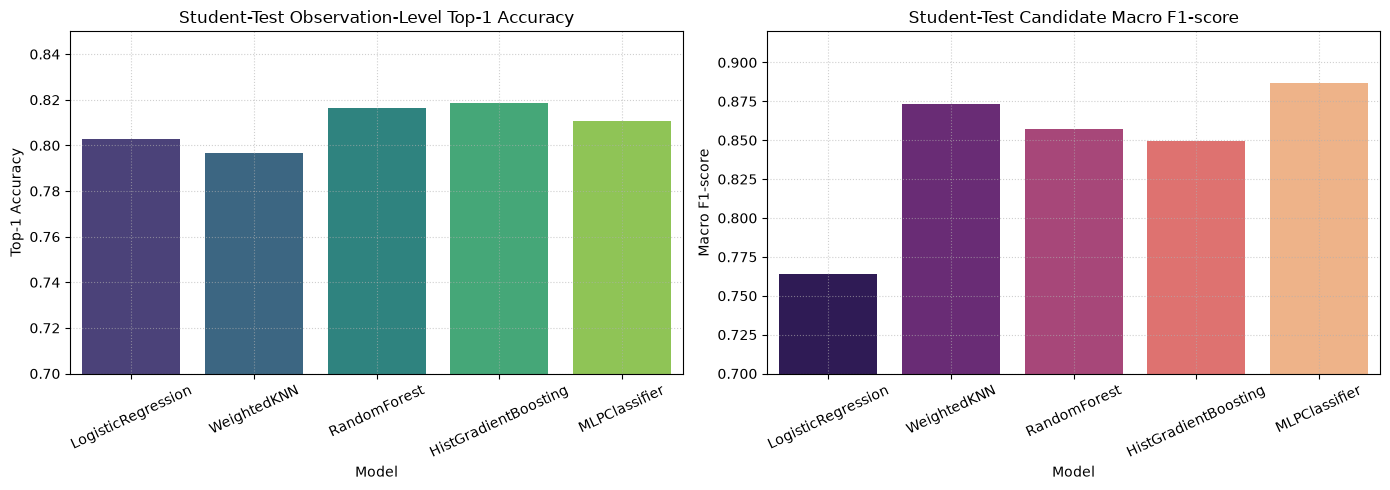

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Student-Test Top-1 Accuracy
sns.barplot(data=comp_df, x="Model", y="Student-Test Top-1 Accuracy", palette="viridis", ax=axes[0])
axes[0].set_title("Student-Test Observation-Level Top-1 Accuracy")
axes[0].set_ylim(0.7, 0.85)
axes[0].set_ylabel("Top-1 Accuracy")
axes[0].tick_params(axis="x", rotation=25)
axes[0].grid(True, linestyle=":", alpha=0.6)

# Plot 2: Macro F1-score comparison
sns.barplot(data=comp_df, x="Model", y="Student-Test Macro F1-score", palette="magma", ax=axes[1])
axes[1].set_title("Student-Test Candidate Macro F1-score")
axes[1].set_ylim(0.7, 0.92)
axes[1].set_ylabel("Macro F1-score")
axes[1].tick_params(axis="x", rotation=25)
axes[1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()


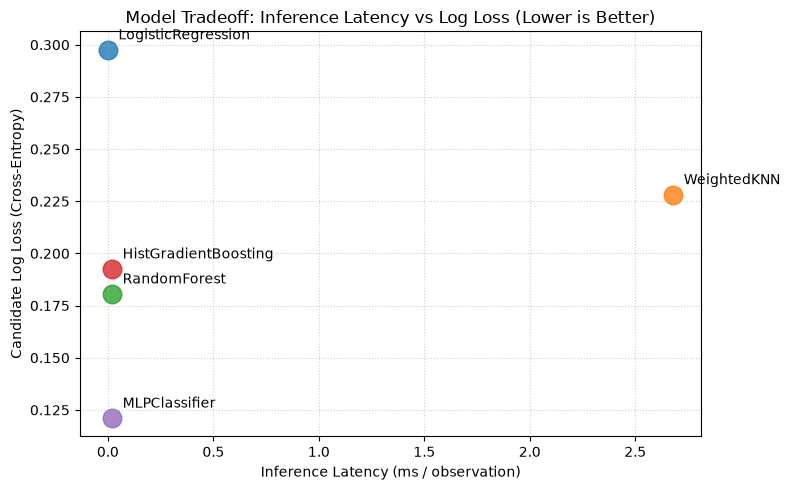

In [4]:
fig, ax = plt.subplots(figsize=(8, 5))
for _, row in comp_df.iterrows():
    ax.scatter(row["Inference Latency (ms/obs)"], row["Student-Test Log Loss"], s=180, alpha=0.8, label=row["Model"])
    ax.annotate(row["Model"], (row["Inference Latency (ms/obs)"] + 0.05, row["Student-Test Log Loss"] + 0.005))

ax.set_title("Model Tradeoff: Inference Latency vs Log Loss (Lower is Better)")
ax.set_xlabel("Inference Latency (ms / observation)")
ax.set_ylabel("Candidate Log Loss (Cross-Entropy)")
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()


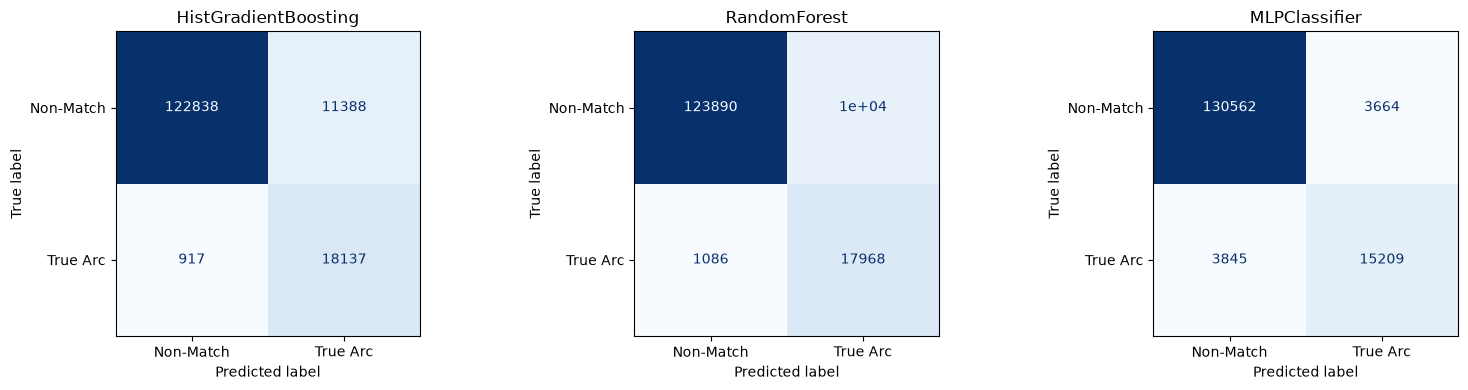

In [5]:
test_df = pd.read_csv(os.path.join(PROJECT_ROOT, "artifacts/results/student_test_features.csv.gz"))
X_test = test_df[FEATURE_COLUMNS].values
y_test = test_df["target"].values

models_to_plot = ["HistGradientBoosting", "RandomForest", "MLPClassifier"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, m_name in enumerate(models_to_plot):
    m_path = os.path.join(PROJECT_ROOT, f"artifacts/models/{m_name}.joblib")
    model = joblib.load(m_path)
    y_pred = (model.predict_proba(X_test)[:, 1] >= 0.5).astype(int)
    cm = confusion_matrix(y_test, y_pred)
    
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Non-Match", "True Arc"])
    disp.plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(f"{m_name}")

plt.tight_layout()
plt.show()


### Model Selection Justification & Recommendation:

1. **Top Observation Accuracy:** `HistGradientBoosting` achieved the highest pointwise Top-1 accuracy (**81.87%**), closely followed by `RandomForest` (**81.64%**).
2. **Top Probability Calibration:** `MLPClassifier` achieved the best Log Loss (**0.1211**) and Macro F1 (**0.8870**), indicating strong probability calibration for candidate emissions.
3. **Inference Latency:** Both `HistGradientBoosting` and `MLPClassifier` run in **0.02 ms per observation**, making them ideal for the live two-laptop deployment.
4. **Recommendation:** Select `HistGradientBoosting` as the primary classifier for Bayesian optimization (Optuna) and use its calibrated probabilities as emission inputs for the HMM/Viterbi route reconstructor.
